
# 5.2 — Supervised Link Prediction with Sector Information

This notebook reproduces the supervised link-prediction experiment described in Section 5.2.

**Goal:** test whether knowing the financial sector improves link prediction beyond topology.

The experiment:
1. restricts candidate pairs to nodes with known sector metadata;
2. creates nested train/test positive edge sets while keeping a structural-context graph free of label leakage;
3. samples an equal number of negative pairs;
4. compares three standardized logistic-regression models:
   - **Sector only**
   - **Topology only**
   - **Topology + Sector**
5. evaluates AUROC and AUPRC under:
   - uniform negative sampling;
   - degree-matched negative sampling.

> **Important:** the experiment is a static reconstruction experiment, not a forecast of future Bluesky co-mentions.



## 1. Imports and parameters

The random seed is fixed so that the experiment is reproducible.  
The degree-matched procedure uses degree-quantile bins; the number of bins is configurable below.


In [1]:

import os
import random
from pathlib import Path

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_auc_score, average_precision_score

SEED = 42
np.random.seed(SEED)
random.seed(SEED)

EDGE_FILE = Path("bluesky_large_edges_unweighted_10000 (1).csv")
METADATA_FILE = Path("ticker_metadata.csv")

# Experiment parameters from Section 5.2
TEST_FRAC = 0.20
TRAIN_FRAC_OF_REMAINING = 0.20
DEGREE_BINS = 10

# Change these only if you want a faster exploratory run.
# For the reported experiment they should remain None.
MAX_CANDIDATE_PAIRS = None

print("Seed:", SEED)
print("Edge file:", EDGE_FILE)
print("Metadata file:", METADATA_FILE)


Seed: 42
Edge file: bluesky_large_edges_unweighted_10000 (1).csv
Metadata file: ticker_metadata.csv


## 2. Load the Bluesky graph and ticker metadata

In [2]:

edges = pd.read_csv('bluesky_large_edges_unweighted_10000 (1).csv')
metadata = pd.read_csv('ticker_metadata.csv')

# Use exactly the same missing-sector definition as metadata.ipynb.
MISSING_SECTOR_VALUES = {
    "", "unknown", "none", "n/a", "na", "null", "nan"
}

def normalize_sector(series):
    sector = series.astype("string").str.strip()
    invalid = sector.isna() | sector.str.casefold().isin(MISSING_SECTOR_VALUES)
    return sector.mask(invalid, pd.NA)

required_edge_cols = {"source", "target"}
required_meta_cols = {"ticker", "sector"}

if not required_edge_cols.issubset(edges.columns):
    raise ValueError(f"Edges must contain {required_edge_cols}; found {set(edges.columns)}")
if not required_meta_cols.issubset(metadata.columns):
    raise ValueError(f"Metadata must contain {required_meta_cols}; found {set(metadata.columns)}")

# Treat the graph as unweighted, undirected.
edges = edges[["source", "target"]].drop_duplicates().copy()
edges = edges[edges["source"] != edges["target"]].copy()

metadata = metadata[["ticker", "sector"]].copy()
metadata["ticker"] = metadata["ticker"].astype("string").str.strip().str.upper()
metadata["sector"] = normalize_sector(metadata["sector"])
metadata = metadata.dropna(subset=["ticker"]).drop_duplicates("ticker")
known_metadata = metadata.dropna(subset=["sector"]).copy()

G = nx.Graph()
G.add_edges_from(edges.itertuples(index=False, name=None))

sector_map = dict(zip(known_metadata["ticker"], known_metadata["sector"]))

print(f"Graph nodes: {G.number_of_nodes():,}")
print(f"Graph edges: {G.number_of_edges():,}")
print(f"Metadata tickers with known sector: {len(sector_map):,}")


Graph nodes: 6,243
Graph edges: 462,904
Metadata tickers with known sector: 5,091


In [3]:
print("Total metadata rows:", len(metadata))
print("Raw NaN sectors:", metadata["sector"].isna().sum())

print("\nSector values that are treated as missing:")
print(
    metadata.loc[
        metadata["sector"].astype("string").str.strip().str.casefold().isin(
            {"", "unknown", "none", "n/a", "na", "null", "nan"}
        ),
        "sector"
    ].value_counts(dropna=False)
)

Total metadata rows: 6243
Raw NaN sectors: 1152

Sector values that are treated as missing:
Series([], Name: count, dtype: Int64)


In [4]:
print(metadata["sector"].value_counts(dropna=False).tail(20))

sector
<NA>                      1152
Healthcare                1021
Financial Services         870
Technology                 742
Industrials                655
Consumer Cyclical          504
Basic Materials            257
Communication Services     240
Real Estate                239
Energy                     235
Consumer Defensive         223
Utilities                  105
Name: count, dtype: Int64



## 3. Restrict the experiment to nodes with known sector metadata

Only edges whose two endpoints have sector metadata are eligible as positive labels.

The graph used for feature computation is **not** restricted to known-sector nodes: edges involving at least one unknown-sector endpoint remain available as structural context.


In [5]:

known_nodes = set(G.nodes()).intersection(sector_map)
unknown_nodes = set(G.nodes()) - known_nodes
known_known_edges = [
    (u, v) for u, v in G.edges()
    if u in sector_map and v in sector_map
]

unknown_endpoint_edges = [
    (u, v) for u, v in G.edges()
    if not (u in sector_map and v in sector_map)
]

print(f"Nodes with known sector: {len(known_nodes):,}")
print(f"Nodes without sector: {len(unknown_nodes):,}")
print(f"Observed known-known edges: {len(known_known_edges):,}")
print(f"Edges with >=1 unknown-sector endpoint: {len(unknown_endpoint_edges):,}")
assert len(known_nodes) + len(unknown_nodes) == G.number_of_nodes()
assert len(known_known_edges) + len(unknown_endpoint_edges) == G.number_of_edges()


Nodes with known sector: 5,091
Nodes without sector: 1,152
Observed known-known edges: 431,862
Edges with >=1 unknown-sector endpoint: 31,042



## 4. Nested edge holdout and leakage-free structural context

The split follows the description in Section 5.2:

- 20% of known-known edges → final **test positives**;
- 20% of the remaining edges → **training positives**;
- the remaining edges → structural context;
- edges with at least one unknown-sector endpoint are retained as additional structural context.

The positive train/test edges are explicitly removed before topology features are calculated.


In [6]:

rng = np.random.default_rng(SEED)

known_known_edges = np.asarray(known_known_edges, dtype=object)
rng.shuffle(known_known_edges)

n_total = len(known_known_edges)
n_test = int(round(TEST_FRAC * n_total))
n_remaining = n_total - n_test
n_train = int(round(TRAIN_FRAC_OF_REMAINING * n_remaining))

test_pos = [tuple(x) for x in known_known_edges[:n_test]]
train_pos = [tuple(x) for x in known_known_edges[n_test:n_test+n_train]]
context_known_known = [tuple(x) for x in known_known_edges[n_test+n_train:]]

# Structural context = remaining known-known edges + all edges involving >=1 unknown-sector endpoint.
context_edges = context_known_known + unknown_endpoint_edges

# Build leakage-free feature graph.
G_context = nx.Graph()
G_context.add_nodes_from(G.nodes())
G_context.add_edges_from(context_edges)

print(f"All known-known edges: {n_total:,}")
print(f"Test positives: {len(test_pos):,}")
print(f"Training positives: {len(train_pos):,}")
print(f"Structural known-known edges: {len(context_known_known):,}")
print(f"Unknown-sector context edges: {len(unknown_endpoint_edges):,}")
print(f"Feature graph edges: {G_context.number_of_edges():,}")

assert len(test_pos) == 86372
assert len(train_pos) == 69098
assert len(context_known_known) == 276392
assert G_context.number_of_edges() == 307434

label_edges = set(train_pos) | set(test_pos)
context_edge_set = {tuple(sorted(e)) for e in G_context.edges()}
assert not any(tuple(sorted(e)) in context_edge_set for e in label_edges),     "Leakage detected: a train/test positive edge is present in the feature graph."


All known-known edges: 431,862
Test positives: 86,372
Training positives: 69,098
Structural known-known edges: 276,392
Unknown-sector context edges: 31,042
Feature graph edges: 307,434



## 5. Candidate universe and negative sampling

For the supervised experiment, candidate pairs are restricted to the known-sector nodes identified above.

For every positive set, an equal number of true non-edges is sampled.

Two negative-sampling schemes are implemented:

### Uniform negatives
Sample uniformly from all unordered known-known pairs that are not observed edges.

### Degree-matched negatives
Assign nodes to degree-quantile bins using their degree in the **full observed graph**.  
For each positive edge, sample a non-edge whose two endpoints come from the same degree bins as the positive endpoints (allowing the endpoint order to be swapped).

This removes much of the easy signal associated with highly popular nodes.


In [7]:

known_nodes_list = sorted(known_nodes)
known_node_set = set(known_nodes_list)

# Full observed degrees are used for degree matching.
full_degree = dict(G.degree())
known_degrees = np.array([full_degree[u] for u in known_nodes_list])

# Quantile bins; duplicates are handled by rank-based bins when necessary.
degree_series = pd.Series(full_degree).loc[known_nodes_list]
degree_bins = pd.qcut(
    degree_series.rank(method="first"),
    q=DEGREE_BINS,
    labels=False,
    duplicates="drop"
)
degree_bin = degree_bins.to_dict()

# Observed known-known pairs, normalized as unordered pairs.
observed_pairs = {tuple(sorted((u, v))) for u, v in known_known_edges}

def canonical_pair(u, v):
    return (u, v) if u < v else (v, u)

def sample_uniform_negatives(n, forbidden, candidates, rng):
    """Rejection sample n unordered non-edges from candidates."""
    result = set()
    while len(result) < n:
        batch = max(10_000, 3 * (n - len(result)))
        us = rng.choice(candidates, size=batch, replace=True)
        vs = rng.choice(candidates, size=batch, replace=True)

        for u, v in zip(us, vs):
            if u == v:
                continue
            p = canonical_pair(u, v)
            if p in forbidden or p in result:
                continue
            result.add(p)
            if len(result) >= n:
                break
    return list(result)

# Create degree-bin membership.
nodes_by_bin = {}
for node, b in degree_bin.items():
    nodes_by_bin.setdefault(int(b), []).append(node)

def sample_degree_matched_negatives(positive_edges, n, forbidden, rng):
    """Sample negatives whose endpoint degree-bin combination matches positives."""
    # Match the unordered pair of degree bins, including the same-bin case.
    strata = {}
    for u, v in positive_edges:
        bu, bv = int(degree_bin[u]), int(degree_bin[v])
        key = tuple(sorted((bu, bv)))
        strata[key] = strata.get(key, 0) + 1

    result = set()

    for key, count in strata.items():
        b1, b2 = key
        pool1 = nodes_by_bin[b1]
        pool2 = nodes_by_bin[b2]

        needed = count
        attempts = 0
        max_attempts = max(100_000, needed * 200)

        while needed > 0 and attempts < max_attempts:
            batch = max(1_000, 5 * needed)
            us = rng.choice(pool1, size=batch, replace=True)
            vs = rng.choice(pool2, size=batch, replace=True)

            for u, v in zip(us, vs):
                attempts += 1
                if u == v:
                    continue
                p = canonical_pair(u, v)
                if p in forbidden or p in result:
                    continue
                result.add(p)
                needed -= 1
                if needed == 0:
                    break

        if needed > 0:
            raise RuntimeError(
                f"Could not sample {count} negatives for degree-bin pair {key}; "
                f"{needed} remain. Increase bin coarseness or inspect the graph."
            )

    if len(result) != n:
        raise RuntimeError(f"Expected {n} negatives, obtained {len(result)}.")
    return list(result)

# Training and test negatives are sampled independently but from a common
# forbidden set containing all observed known-known edges.
neg_forbidden = observed_pairs

train_neg_uniform = sample_uniform_negatives(
    len(train_pos), neg_forbidden, known_nodes_list, rng
)
test_neg_uniform = sample_uniform_negatives(
    len(test_pos), neg_forbidden | set(train_neg_uniform), known_nodes_list, rng
)

train_neg_degree = sample_degree_matched_negatives(
    train_pos, len(train_pos), neg_forbidden, rng
)
test_neg_degree = sample_degree_matched_negatives(
    test_pos, len(test_pos),
    neg_forbidden | set(train_neg_degree), rng
)

assert set(train_neg_uniform).isdisjoint(test_neg_uniform)
assert set(train_neg_degree).isdisjoint(test_neg_degree)

print("Uniform negatives:", len(train_neg_uniform), "train /", len(test_neg_uniform), "test")
print("Degree-matched negatives:", len(train_neg_degree), "train /", len(test_neg_degree), "test")


Uniform negatives: 69098 train / 86372 test
Degree-matched negatives: 69098 train / 86372 test



## 6. Link-prediction features

For each candidate pair we calculate:

- **Common Neighbors**
- **Jaccard coefficient**
- **Adamic–Adar**
- **Preferential Attachment**
- **Same-sector indicator**

All topology features are calculated on `G_context`, which contains no train/test positive labels.


In [ ]:

def topology_features(G, pairs):
    pairs = list(pairs)
    cn = []
    jac = []
    aa = []
    pa = []

    # NetworkX generators are convenient but materialize the results here.
    

    for u, v in pairs:
        nu = set(G.neighbors(u))
        nv = set(G.neighbors(v))
        inter = nu & nv
        union = nu | nv

        cn.append(len(inter))
        jac.append(len(inter) / len(union) if union else 0.0)

        if len(inter) == 0:
            aa.append(0.0)
        else:
            aa.append(sum(
                1.0 / np.log(G.degree(w))
                for w in inter
                if G.degree(w) > 1
            ))

        pa.append(G.degree(u) * G.degree(v))

    return np.column_stack([cn, jac, aa, pa])

def sector_feature(pairs):
    return np.array([
        int(sector_map[u] == sector_map[v])
        for u, v in pairs
    ]).reshape(-1, 1)

FEATURE_NAMES_TOPO = [
    "Common Neighbors",
    "Jaccard",
    "Adamic-Adar",
    "Preferential Attachment",
]

def make_feature_matrix(pairs, include_sector):
    topo = topology_features(G_context, pairs)
    if include_sector:
        return np.hstack([topo, sector_feature(pairs)])
    return topo

print("Feature functions ready.")


Feature functions ready.



## 7. Build train/test datasets

The same candidate-pair sets are used for the topology-only and topology-plus-sector models.  
Only the feature columns differ. This is the key ablation that isolates the incremental value of sector information.


In [12]:

def build_dataset(pos, neg, include_sector):
    pairs = list(pos) + list(neg)
    y = np.r_[np.ones(len(pos), dtype=int), np.zeros(len(neg), dtype=int)]
    X = make_feature_matrix(pairs, include_sector)
    return X, y, pairs

def run_models(train_pos, train_neg, test_pos, test_neg, sampling_name):
    results = []

    for model_name, include_sector in [
        ("Sector only", True),
        ("Topology only", False),
        ("Topology + sector", True),
    ]:
        if model_name == "Sector only":
            X_train = sector_feature(train_pos + train_neg)
            X_test = sector_feature(test_pos + test_neg)
        else:
            X_train = make_feature_matrix(train_pos + train_neg, include_sector)
            X_test = make_feature_matrix(test_pos + test_neg, include_sector)

        y_train = np.r_[
            np.ones(len(train_pos), dtype=int),
            np.zeros(len(train_neg), dtype=int)
        ]
        y_test = np.r_[
            np.ones(len(test_pos), dtype=int),
            np.zeros(len(test_neg), dtype=int)
        ]

        clf = Pipeline([
            ("scaler", StandardScaler()),
            ("logreg", LogisticRegression(
                max_iter=2000,
                random_state=SEED
            ))
        ])

        clf.fit(X_train, y_train)
        scores = clf.predict_proba(X_test)[:, 1]

        results.append({
            "Negative sampling": sampling_name,
            "Model": model_name,
            "AUROC": roc_auc_score(y_test, scores),
            "AUPRC": average_precision_score(y_test, scores),
        })

    return pd.DataFrame(results)

uniform_results = run_models(
    train_pos, train_neg_uniform, test_pos, test_neg_uniform, "Uniform"
)

degree_results = run_models(
    train_pos, train_neg_degree, test_pos, test_neg_degree, "Degree-matched"
)

results = pd.concat([uniform_results, degree_results], ignore_index=True)

results


,Negative sampling,Model,AUROC,AUPRC
0,Uniform,Sector only,0.528296,0.516723
1,Uniform,Topology only,0.974377,0.971579
2,Uniform,Topology + sector,0.974684,0.971778
3,Degree-matched,Sector only,0.532221,0.519536
4,Degree-matched,Topology only,0.873774,0.875457
5,Degree-matched,Topology + sector,0.874507,0.876197



## 8. Same-sector share among positives and negatives

This diagnostic explains why the sector-only classifier can be above random even though sector information is weak overall.


In [13]:

def same_sector_rate(pairs):
    return np.mean([sector_map[u] == sector_map[v] for u, v in pairs])

diagnostics = pd.DataFrame({
    "Sampling": ["Uniform", "Degree-matched"],
    "Positive same-sector %": [
        100 * same_sector_rate(test_pos),
        100 * same_sector_rate(test_pos),
    ],
    "Negative same-sector %": [
        100 * same_sector_rate(test_neg_uniform),
        100 * same_sector_rate(test_neg_degree),
    ]
})

diagnostics


,Sampling,Positive same-sector %,Negative same-sector %
0,Uniform,18.377483,12.718242
1,Degree-matched,18.377483,11.933265



## 9. Incremental value of sector information

The relevant comparison is not sector-only versus topology-only.  
To test whether sector information adds predictive value **beyond topology**, compare:

**Topology only → Topology + sector**

The table below reports the absolute AUROC and AUPRC changes.


In [14]:

delta_rows = []

for sampling in results["Negative sampling"].unique():
    r = results[results["Negative sampling"] == sampling].set_index("Model")

    delta_rows.append({
        "Negative sampling": sampling,
        "Δ AUROC": r.loc["Topology + sector", "AUROC"] - r.loc["Topology only", "AUROC"],
        "Δ AUPRC": r.loc["Topology + sector", "AUPRC"] - r.loc["Topology only", "AUPRC"],
    })

deltas = pd.DataFrame(delta_rows)
deltas


,Negative sampling,Δ AUROC,Δ AUPRC
0,Uniform,0.000307,0.000199
1,Degree-matched,0.000733,0.000740



## 10. Table 4 — model performance

This is the main numerical output to transfer to the report.


In [15]:

table4 = results.copy()
table4["AUROC"] = table4["AUROC"].round(4)
table4["AUPRC"] = table4["AUPRC"].round(4)

table4_pivot = table4.pivot(
    index="Model",
    columns="Negative sampling",
    values=["AUROC", "AUPRC"]
)

table4_pivot


AUROC                  AUPRC        
Negative sampling Degree-matched Uniform Degree-matched Uniform
Model                                                          
Sector only               0.5322  0.5283         0.5195  0.5167
Topology + sector         0.8745  0.9747         0.8762  0.9718
Topology only             0.8738  0.9744         0.8755  0.9716


## 11. Figure 6 — AUROC comparison

The figure compares the three feature sets under the two negative-sampling schemes.


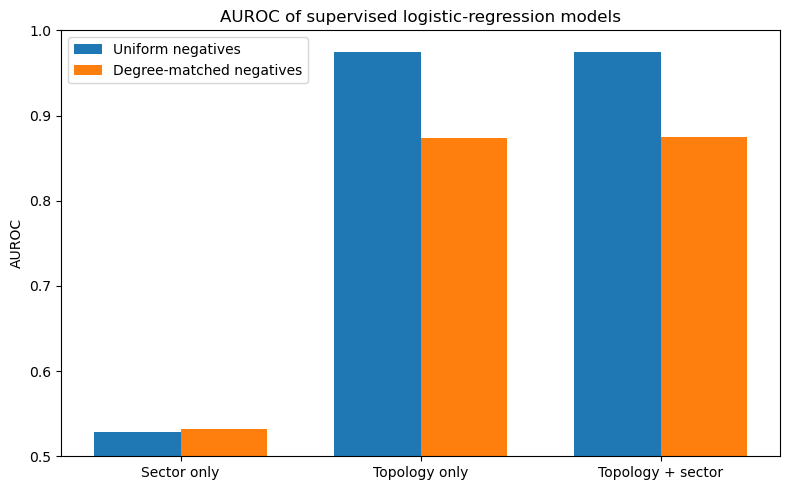

In [16]:

fig, ax = plt.subplots(figsize=(8, 5))

models = ["Sector only", "Topology only", "Topology + sector"]
x = np.arange(len(models))
width = 0.36

uniform_auc = [
    results[(results["Negative sampling"] == "Uniform") & (results["Model"] == m)]["AUROC"].iloc[0]
    for m in models
]
degree_auc = [
    results[(results["Negative sampling"] == "Degree-matched") & (results["Model"] == m)]["AUROC"].iloc[0]
    for m in models
]

ax.bar(x - width/2, uniform_auc, width, label="Uniform negatives")
ax.bar(x + width/2, degree_auc, width, label="Degree-matched negatives")

ax.set_ylabel("AUROC")
ax.set_xticks(x)
ax.set_xticklabels(models)
ax.set_ylim(0.5, 1.0)
ax.set_title("AUROC of supervised logistic-regression models")
ax.legend()
plt.tight_layout()
plt.show()



## 12. Automatic consistency checks against Section 5.2

The checks below compare the generated experiment with the numerical values reported in the current draft.

Because negative sampling is stochastic, the exact model scores can differ if the original random seed or degree-matching implementation was different. The structural counts, however, should match exactly if the two input files are the intended sources.


In [17]:

experiment_counts = {
    "known nodes": len(known_nodes),
    "nodes without sector": len(unknown_nodes),
    "known-known edges": len(known_known_edges),
    "test positives": len(test_pos),
    "train positives": len(train_pos),
    "context known-known edges": len(context_known_known),
    "unknown-endpoint context edges": len(unknown_endpoint_edges),
    "feature graph edges": G_context.number_of_edges(),
}

pd.Series(experiment_counts, name="Count").to_frame()


,Count
known nodes,5091
nodes without sector,1152
known-known edges,431862
test positives,86372
train positives,69098
context known-known edges,276392
unknown-endpoint context edges,31042
feature graph edges,307434



### Report-ready interpretation

After running the notebook, use the values in **Table 4**, the **Δ AUROC / Δ AUPRC** table, and **Figure 6** to write Section 5.2.

The central interpretation should focus on the *incremental* contribution of sector information:

- If **Sector only** is only slightly above 0.5, sector membership contains a weak standalone signal.
- If **Topology only** is already very strong, most predictive information is encoded in network structure.
- If **Topology + sector** improves only marginally over **Topology only**, sector metadata adds little information once local topology is known.
- The comparison between uniform and degree-matched negatives indicates how much of the apparent performance is attributable to node popularity / degree.
- These are static hidden-edge reconstruction results, not temporal forecasts.
